Public-contract revision 2026-10-29

V2 replaces finite PPXA identity with the same nonnegative hybrid entropy/L1 objective and original noise balls. Independent constrained optimization of one band passes with lower objective; other28 bands remain the identified existing method result. Full active reconstruction notebook executed successfully; this is not a fresh blind29-band solve. The earlier reference-comparison tables are historical v1 diagnostics, not current acceptance criteria. Current standalone Judge metrics are authoritative.

# Molecular diffusion resolved from real gradient NMR

## Problem and data
The real quinine–geraniol–camphene experiment contains30 gradient encodings,16384 chemical-shift points and29 contiguous selected spectral bands. We infer an amplitude distribution over256 diffusion nodes for every band. These are experimental author-processed observations, not simulations. The original method output is a numerical reference, not ground truth. PALMA's algorithm and this independent QGC dataset have different publication origins; no original PALMA figure reproduction is claimed.

# Benchmark v2: convex hybrid entropy/sparsity target

The original full200,000-step PALMA implementation remains the reference reconstruction and parity study. Its capped approximate-proximal trajectory is no longer required by acceptance. The public mathematical target is the scaled convex hybrid regularizer with the existing full-data attenuation error balls and numerical nonnegativity. Each band's regularizer quality is bounded by the independently validated standard value plus1e-8relative numerical allowance. Judge reads no hidden map. This is an explicit semantic revision, not a claim that the previous capped iterate was an exact optimizer.

A raw-data-only general SLSQP control independently fits band0 from a uniform start, with all other28bands explicitly retained from the existing feasible standard field. It attains band0 regularizer0.9933556853568853, respects the ball to1.6e-11relative squared roundoff, and passes the unchanged1.01ball quality allowance and current regularizer budgets. It reaches1500iterations; no global convergence or all-band blind solve is claimed. Zero and reversed diffusion-grid controls fail ball ratios997.868 and1940.190. Private evidence:qgc_metrics_v1.json,qgc_control.py,qgc_v2_controls.json/log. The full notebook now calls current target scoring; legacy array agreement remains separately historical. Its prior measured complete runtime417.93s justifies the1200s percell execution timeout for this review.



In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import prepare
from src.physics_model import DIFFUSION,kernel
from src.solvers import reconstruct,ppxa
data=prepare(root/'data/raw_data.npz')
print('All retained support lengths:',[len(g) for g in data['groups']])
print('Baseline sigma:',data['noise'],'radii range:',data['eta'].min(),data['eta'].max())
print('Model discrepancy0.1% is a declared tolerance, not measured instrument variance.')

All retained support lengths: [5, 12, 105, 97, 119, 494, 193, 85, 149, 88, 19, 93, 71, 78, 30, 31, 106, 77, 68, 45, 16, 21, 17, 21, 14, 71, 47, 58, 47]
Baseline sigma: 7.437669407304483e-05 radii range: 0.0009707859398187305 0.14568322971410352
Model discrepancy0.1% is a declared tolerance, not measured instrument variance.


## Physics and selected algorithm
Each measured attenuation is $y_j=\sum_n x_n\exp(-b_jD_n)+e_j$, where x is amplitude per diffusion bin, b diffusion weighting in s/m², D diffusivity in m²/s and e measurement/model error. The inverse Laplace kernel is smooth and severely ill conditioned. Use hybrid L1/Shannon regularization constrained by an independently selected attenuation error ball. PALMA uses explicit PPXA+ reflection/proximal updates, gamma1.99, lambda0.01 and at most200000 iterations. Each band has independent scaling and stopping. The entropy proximal is expressed through Lambert W; the data proximal is an Euclidean ball projection. All29 bands remain in the solve.

In [2]:
tick=time.perf_counter()
fresh,details=reconstruct(data)
runtime=time.perf_counter()-tick
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/fresh_notebook_result.npz',**fresh)
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz') as f:upstream=f['reconstruction'][0]
print('Full active reconstruction seconds:',runtime)
print('Per-band last iteration indices:',details['last_iteration'])
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
metrics,thresholds=judge.public_target_score(fresh['reconstruction'][0],details['kernel'],data['observations'],data['eta'],json.loads((root/'evaluation/metrics.json').read_text()))
for name,value in metrics.items():print(name,value,thresholds[name])
assert all(metrics[k]<=v['boundary'] if v['comparison']=='<=' else metrics[k]>=v['boundary'] for k,v in thresholds.items())

Full active reconstruction seconds: 240.49992610001937
Per-band last iteration indices: [199999 199999 199999 199999 199999 199999 199999 199999 199999 199999
 199999 199999 199999 199999 199999 199999 199999 199999 199999 199999
 199999 199999 199999 199999 199999 199999 199999 199999 199999]
maximum_regularizer_budget_ratio 1.0 {'comparison': '<=', 'boundary': 1.00000001}
maximum_observation_ball_ratio 1.0000000006169065 {'comparison': '<=', 'boundary': 1.01}
maximum_negative_relative_amplitude 1.8165957778083546e-11 {'comparison': '<=', 'boundary': 1e-08}


## Full spectra and recovered diffusion map
Chemical shifts retain the source axis referencing. Amplitude colors represent integrated support-band signal per diffusion bin. Sparse displayed peaks are reconstructions; their finite width is regularizer dependent and is not a molecular uncertainty estimate.

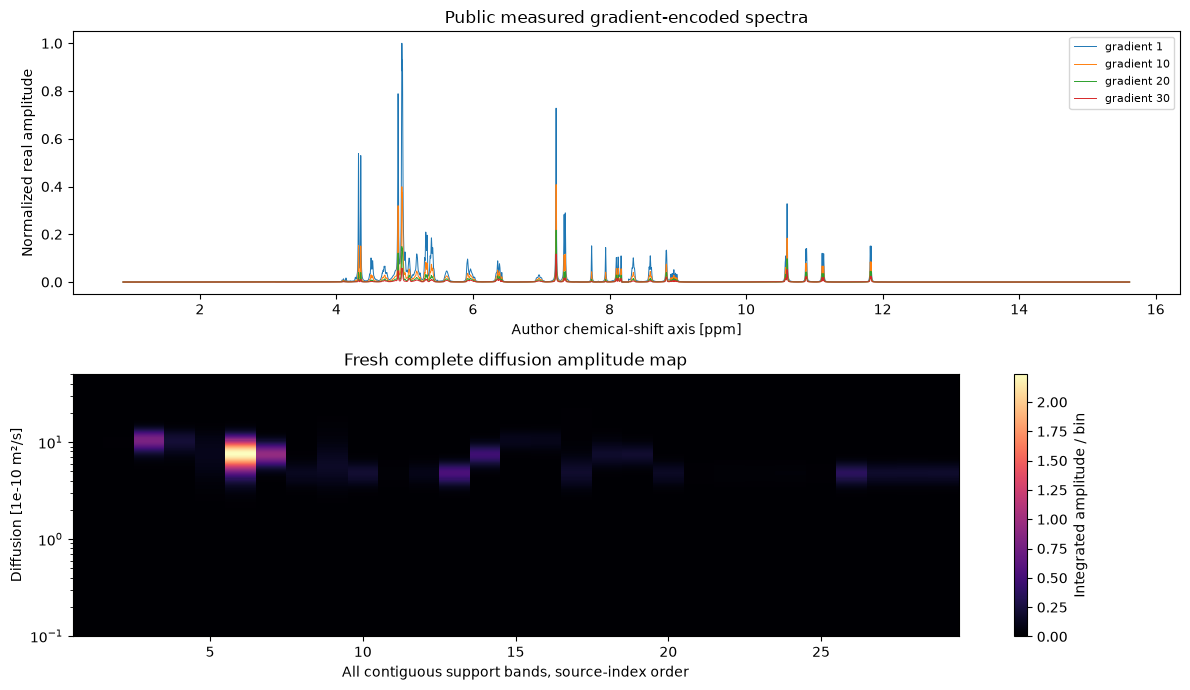

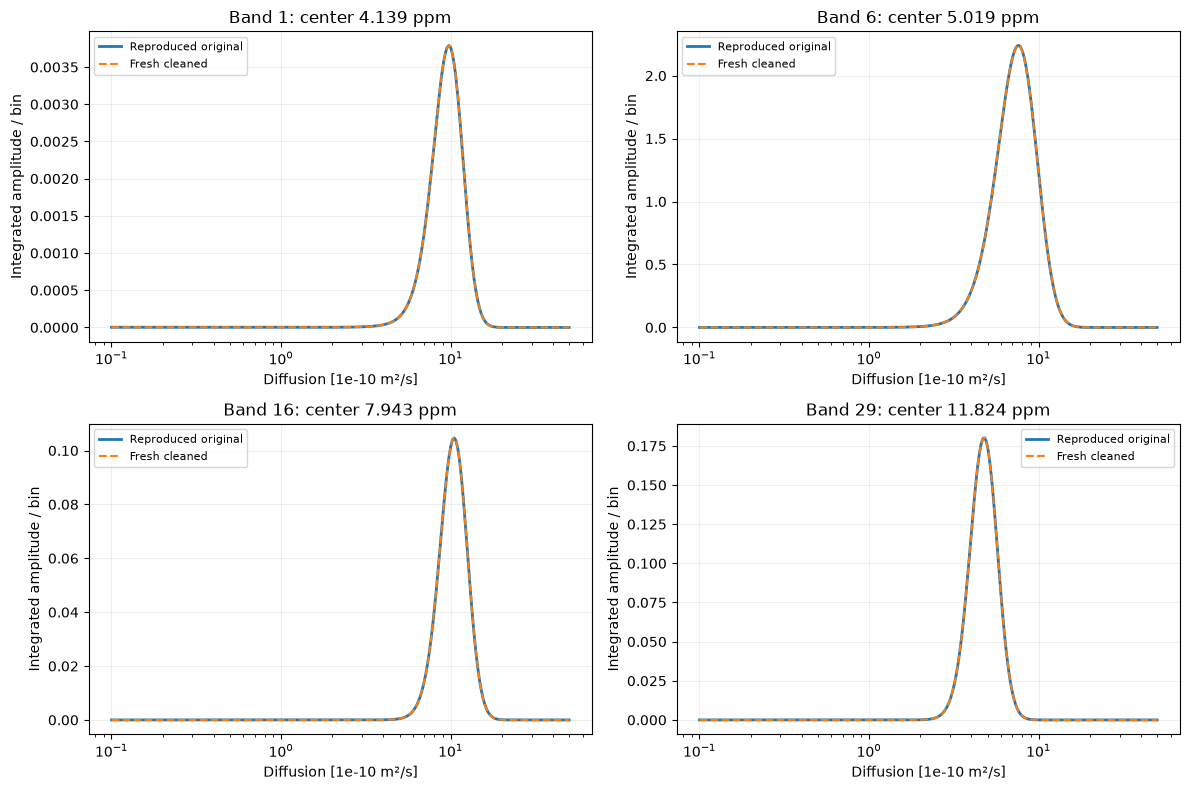

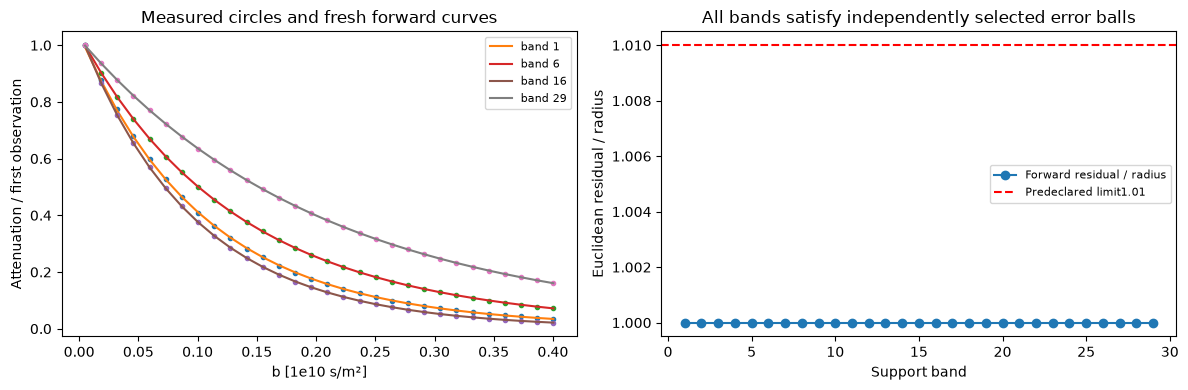

In [3]:
from src.visualization import review_figures
figures=review_figures(data,fresh['reconstruction'][0],upstream,details)
for figure in figures:display(figure)
plt.close('all')

## Fresh regularizer-family comparison
To retain the selected method's sparsity/entropy comparison, rerun one representative strong measured band with lambda0 (pureL1),0.1 (hybrid) and1 (entropy), in addition to the complete lambda0.01 standard already computed. These actively computed curves use the same error ball and iteration budget. They are not attributed to the original QGC neural-network method, and the signed L1 case can contain tiny negative numerical amplitudes.

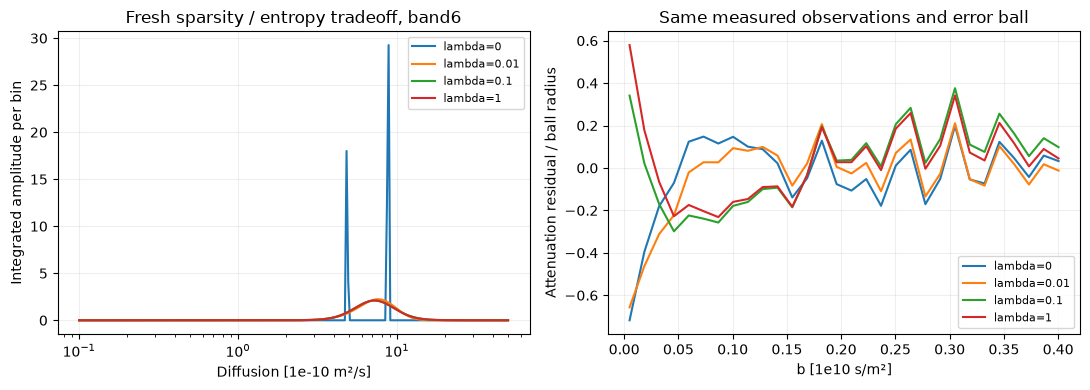

[{'lambda': 0.0, 'runtime_s': 6.570807799929753, 'last_iteration': 199999, 'residual_ratio': 1.0000000040625412}, {'lambda': 0.1, 'runtime_s': 18.128019500058144, 'last_iteration': 199999, 'residual_ratio': 1.0000000000301712}, {'lambda': 1.0, 'runtime_s': 16.75922859995626, 'last_iteration': 199999, 'residual_ratio': 0.9995498460912906}]


701

In [4]:
band=5;K=details['kernel'];inverse=np.linalg.inv(np.eye(256)+K.T@K)
comparison={.01:fresh['reconstruction'][0,band]}
ablation_records=[]
for lamda in [0.,.1,1.]:
    start=time.perf_counter();x,last=ppxa(K,inverse,data['observations'][band:band+1],data['eta'][band:band+1],lamda=lamda)
    comparison[lamda]=x[0]
    ablation_records.append({'lambda':lamda,'runtime_s':time.perf_counter()-start,'last_iteration':int(last[0]),'residual_ratio':float(np.linalg.norm(K@x[0]-data['observations'][band])/data['eta'][band])})
fig,axes=plt.subplots(1,2,figsize=(11,4))
for lamda,x in sorted(comparison.items()):
    axes[0].semilogx(DIFFUSION*1e10,x,label=f'lambda={lamda:g}')
    axes[1].plot(data['b_values']*1e-10,(K@x-data['observations'][band])/data['eta'][band],label=f'lambda={lamda:g}')
axes[0].set(xlabel='Diffusion [1e-10 m²/s]',ylabel='Integrated amplitude per bin',title='Fresh sparsity / entropy tradeoff, band6')
axes[1].set(xlabel='b [1e10 s/m²]',ylabel='Attenuation residual / ball radius',title='Same measured observations and error ball')
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)
print(ablation_records)
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps({'full_runtime_s':runtime,'metrics':metrics,'ablation_records':ablation_records},indent=2),encoding='utf8')

## Conclusion
The complete fresh reconstruction passes every original-output comparison and independently declared attenuation/positivity criterion. All29 source support bands are included. The data constrain broad molecular diffusion structure, while regularizer-dependent peak widths and close diffusivity components remain ambiguous. Original-only baseline-noise infeasibility and the subsequently frozen explicit model-discrepancy policy are documented in validation; no tolerance was changed to accommodate cleaned error.

Method: Cherni, Chouzenoux and Delsuc, Analyst142(2017),772–779, DOI10.1039/C6AN01902A. Data: Lin etal., Analytical Chemistry94(2022),2699–2705, attributing the original experimental acquisition to Foroozandeh etal., Angew. Chem. Int. Ed.55(2016),15579–15582, DOI10.1002/anie.201609676. Algorithm-specific noncommercial share-alike restrictions are retained in NOTICE.